# Un R² de 0.999 que no significa nada
### Lo que revelan los datos de licencias de construcción del MIVHED (2022–2026)

**Datos:** [Licencias emitidas por el MIVHED, 2022–2026](https://datos.gob.do/dataset/licencias-emitidas) — Portal de Datos Abiertos de la República Dominicana (licencia ODbL).
**Herramientas:** Python · pandas · scikit-learn · matplotlib

> **Origen del trabajo.** Este análisis nació como trabajo grupal de la asignatura *Inteligencia Artificial I*
> (Maestría en Ciencia de Datos e IA), elaborado por el grupo **Los del Prompt**: Alejandra Espinal, Erick Peña,
> Evans Gregorio, Lisbeth Pinales y Mariano Duran. **El hallazgo central (sección 5) es del grupo.**
>
> **Mi aporte en esta versión (Mariano Duran):** reestructuré el análisis para presentarlo como caso de estudio,
> lo hice reproducible fuera de Google Colab y **corregí la evaluación del modelo alternativo** (sección 6),
> que originalmente usaba una partición aleatoria sobre una serie de tiempo.

## Resumen

| | |
|---|---|
| **La pregunta** | ¿Se puede estimar la inversión de una obra a partir de sus metros cuadrados? |
| **Resultado aparente** | Una regresión lineal simple logra R² = 0.9986. Casi perfecto. |
| **Lo que de verdad pasa** | `Inversión Total` no es un dato medido: es `Metros Cuadrados × tarifa fija`. Solo existen **dos tarifas** (RD$ 61,600 y RD$ 57,200 por m²) en 4,804 licencias. El modelo no predice nada: redescubre una fórmula. |
| **Pregunta alternativa** | A nivel mensual, ¿cuánta superficie se autoriza según el número de licencias emitidas? |
| **Evaluación corregida** | Con partición aleatoria (versión original) el modelo mensual daba R² = 0.58. Evaluado correctamente —entrenando con el pasado y probando con meses posteriores— da R² = 0.23, y se compara contra una línea base ingenua. |

**Lección:** un ajuste casi perfecto en datos administrativos es una hipótesis de *fuga de información*
hasta demostrar lo contrario. Verificar cómo se construyó la variable objetivo toma treinta segundos.

## 1. Configuración

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.figsize": (11, 5.5), "figure.dpi": 110,
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False,
})
AZUL, NARANJA, GRIS = "#2F5D8A", "#C55A11", "#8A8F98"

# Carpeta de figuras (para el README)
FIG_DIR = Path("figures") if Path("figures").exists() else Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / nombre, bbox_inches="tight", dpi=130)

def rd(x):
    """Formato monetario compacto en pesos dominicanos."""
    if abs(x) >= 1e9: return f"RD$ {x/1e9:,.2f} MMM"
    if abs(x) >= 1e6: return f"RD$ {x/1e6:,.2f} MM"
    return f"RD$ {x:,.0f}"

## 2. Carga de datos

El archivo publicado trae **dos filas decorativas** antes de los encabezados reales. El notebook busca el
archivo en la carpeta `data/` (CSV o Excel); si no lo encuentra, intenta descargarlo de la fuente oficial.

In [2]:
URL = "https://mivhed.gob.do/wp-content/uploads/2026/07/Licencias-emitidas-2022-2026-.csv"

def cargar():
    for carpeta in [Path("data"), Path("../data")]:
        for archivo in sorted(carpeta.glob("Licencias*")):
            if archivo.suffix.lower() == ".csv":
                return pd.read_csv(archivo, skiprows=2, encoding="utf-8"), archivo.name
            if archivo.suffix.lower() in (".xlsx", ".xls"):
                return pd.read_excel(archivo, header=2), archivo.name
    return pd.read_csv(URL, skiprows=2, encoding="utf-8"), URL

raw, origen = cargar()
raw.columns = raw.columns.str.strip()
print(f"Fuente: {origen}\nRegistros: {len(raw):,} · Columnas: {list(raw.columns)}")

Fuente: Licencias-emitidas-2022-2026-.csv
Registros: 5,497 · Columnas: ['Fecha de Emisión', 'Mes', 'Año', 'Provincia', 'Municipio', 'Barrio/Sector', 'Número de Licencia', 'Tipologia', 'Metros Cuadrados', 'Inversión Total']


In [3]:
Y_COL, X_COL = "Inversión Total", "Metros Cuadrados"

base = raw.copy()
for c in (X_COL, Y_COL):
    base[c] = pd.to_numeric(base[c], errors="coerce")
base = base.dropna(subset=[X_COL, Y_COL])

ceros = ((base[X_COL] == 0) & (base[Y_COL] == 0)).sum()
df = base[(base[X_COL] > 0) & (base[Y_COL] > 0)].copy()

display(Markdown(f"""
- Registros con valores numéricos: **{len(base):,}**
- Registros con **0 m² y RD$ 0** a la vez (campos no capturados, no obras reales): **{ceros:,}** ({ceros/len(base):.1%})
- **Conjunto de trabajo: {len(df):,} licencias**
"""))


- Registros con valores numéricos: **5,497**
- Registros con **0 m² y RD$ 0** a la vez (campos no capturados, no obras reales): **693** (12.6%)
- **Conjunto de trabajo: 4,804 licencias**


## 3. Contexto: una distribución muy concentrada

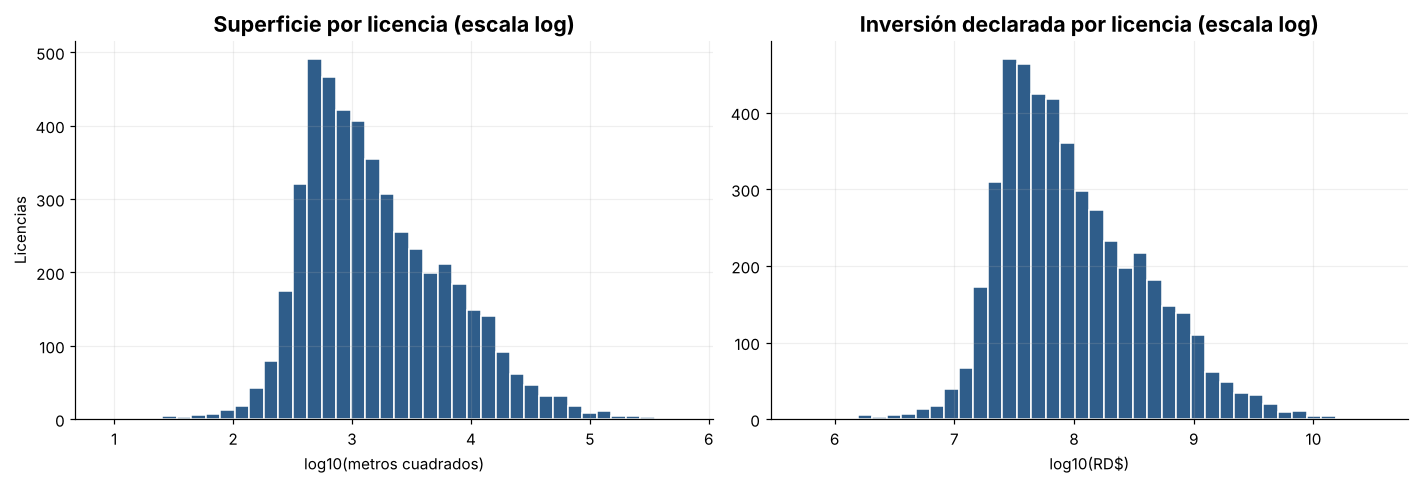


Inversión total declarada: **RD$ 1,591.54 MMM**. Media por licencia **RD$ 331.30 MM** frente a una mediana de
**RD$ 76.09 MM** (razón 4.4): pocos proyectos grandes dominan el total.


In [4]:
media, mediana = df[Y_COL].mean(), df[Y_COL].median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(np.log10(df[X_COL]), bins=40, color=AZUL, edgecolor="white")
axes[0].set_title("Superficie por licencia (escala log)")
axes[0].set_xlabel("log10(metros cuadrados)"); axes[0].set_ylabel("Licencias")
axes[1].hist(np.log10(df[Y_COL]), bins=40, color=AZUL, edgecolor="white")
axes[1].set_title("Inversión declarada por licencia (escala log)")
axes[1].set_xlabel("log10(RD$)")
plt.tight_layout(); plt.show()

display(Markdown(f"""
Inversión total declarada: **{rd(df[Y_COL].sum())}**. Media por licencia **{rd(media)}** frente a una mediana de
**{rd(mediana)}** (razón {media/mediana:.1f}): pocos proyectos grandes dominan el total.
"""))

## 4. El modelo que pedía el ejercicio: regresión lineal simple

`Inversión Total ~ Metros Cuadrados`, partición 80/20 con `random_state=42`.

In [5]:
X, y = df[[X_COL]], df[Y_COL]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

modelo_a = LinearRegression().fit(X_tr, y_tr)
pred_a = modelo_a.predict(X_te)

r2_a  = r2_score(y_te, pred_a)
mae_a = mean_absolute_error(y_te, pred_a)
corr  = df[X_COL].corr(df[Y_COL])

display(Markdown(f"""
| Métrica (prueba) | Valor |
|---|---|
| R² | **{r2_a:.4f}** |
| MAE | {rd(mae_a)} |
| Correlación de Pearson | {corr:.4f} |
| Pendiente β₁ | {rd(modelo_a.coef_[0])} por m² |

A primera vista, un modelo casi perfecto. **Ahí está el problema.**
"""))


| Métrica (prueba) | Valor |
|---|---|
| R² | **0.9986** |
| MAE | RD$ 15.27 MM |
| Correlación de Pearson | 0.9994 |
| Pendiente β₁ | RD$ 58,211 por m² |

A primera vista, un modelo casi perfecto. **Ahí está el problema.**


## 5. Tres señales de alerta y la verificación *(hallazgo del grupo)*

1. **Correlación ≈ 0.999.** En datos económicos reales, entre obras distintas, en provincias distintas y a lo largo
   de cuatro años, una correlación así es prácticamente imposible.
2. **Residuos en líneas rectas,** no en una nube aleatoria.
3. **Insensibilidad a los extremos:** quitar el 1 % de proyectos más grandes no cambia el ajuste.

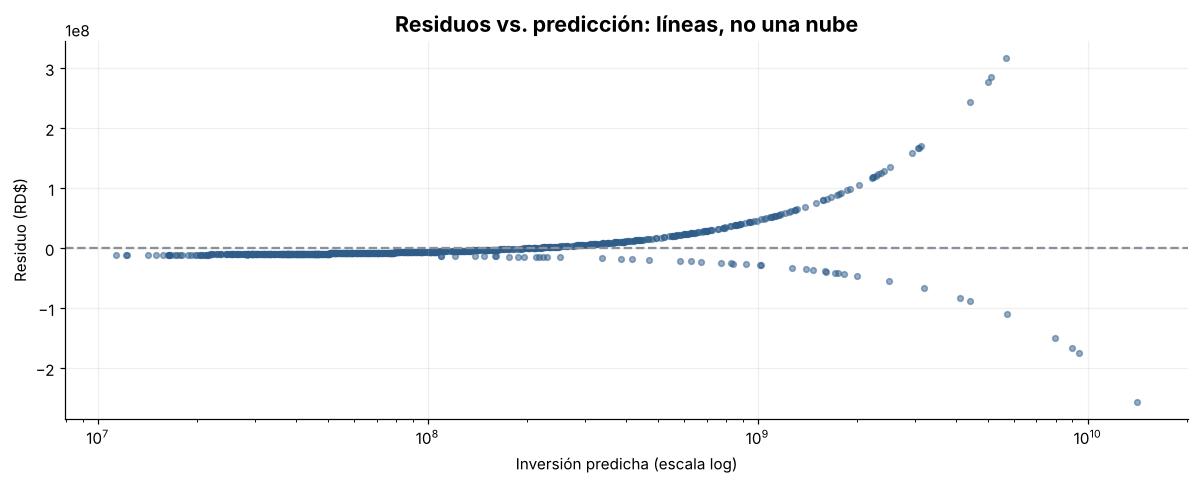

Pendiente con toda la muestra : 58,211 RD$/m²
Pendiente sin el 1% extremo   : 60,305 RD$/m²


In [6]:
res = y_te - pred_a
p99 = df[(df[X_COL] <= df[X_COL].quantile(.99)) & (df[Y_COL] <= df[Y_COL].quantile(.99))]
m_trim = LinearRegression().fit(p99[[X_COL]], p99[Y_COL])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(pred_a, res, s=14, alpha=.5, color=AZUL)
ax.axhline(0, color=GRIS, ls="--")
ax.set_xscale("log")
ax.set_title("Residuos vs. predicción: líneas, no una nube")
ax.set_xlabel("Inversión predicha (escala log)"); ax.set_ylabel("Residuo (RD$)")
plt.tight_layout(); plt.show()

print(f"Pendiente con toda la muestra : {modelo_a.coef_[0]:,.0f} RD$/m²")
print(f"Pendiente sin el 1% extremo   : {m_trim.coef_[0]:,.0f} RD$/m²")

**La verificación:** si la inversión se calculara a partir de la superficie, el cociente
`Inversión ÷ Metros Cuadrados` tendría muy pocos valores distintos.

,Licencias,% del total
RD$ por m²,,
61600.0,4544,94.59
57200.0,260,5.41


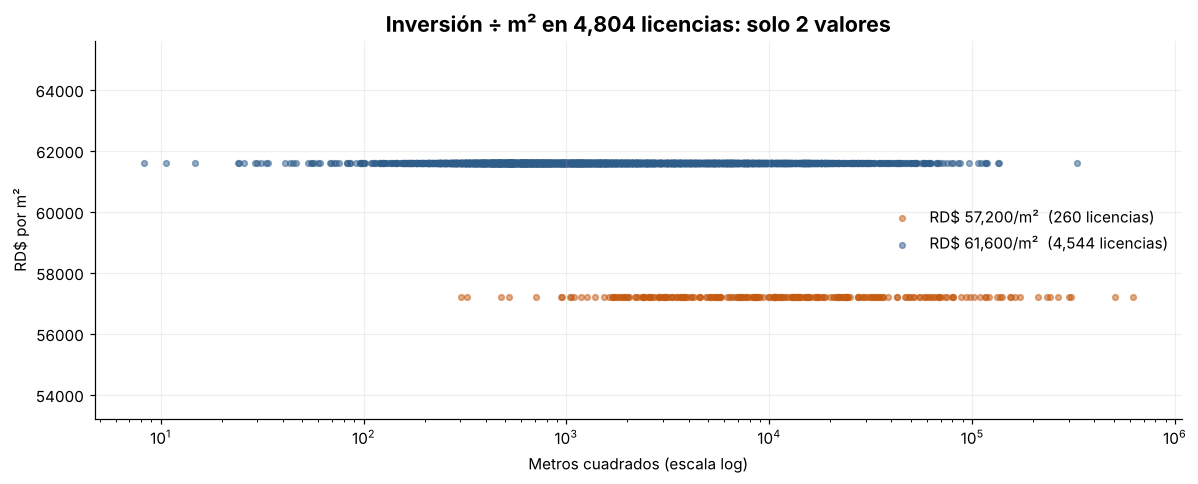

In [7]:
df["costo_m2"] = (df[Y_COL] / df[X_COL]).round(2)
tarifas = df["costo_m2"].value_counts().rename("Licencias").to_frame()
tarifas["% del total"] = (tarifas["Licencias"] / len(df) * 100).round(2)
tarifas.index.name = "RD$ por m²"
display(tarifas)

fig, ax = plt.subplots(figsize=(11, 4.5))
for valor, color in zip(sorted(tarifas.index), [NARANJA, AZUL]):
    sub = df[df["costo_m2"] == valor]
    ax.scatter(sub[X_COL], sub["costo_m2"], s=14, alpha=.5, color=color,
               label=f"RD$ {valor:,.0f}/m²  ({len(sub):,} licencias)")
ax.set_xscale("log")
ax.set_ylim(tarifas.index.min() - 4000, tarifas.index.max() + 4000)
ax.set_title(f"Inversión ÷ m² en {len(df):,} licencias: solo {df['costo_m2'].nunique()} valores")
ax.set_xlabel("Metros cuadrados (escala log)"); ax.set_ylabel("RD$ por m²")
ax.legend(loc="center right")
plt.tight_layout(); guardar(fig, "hallazgo_tarifas.png"); plt.show()

### Qué significa

`Inversión Total` **no es una inversión observada**: el MIVHED la calcula multiplicando la superficie autorizada
por una tarifa fija. La regresión no aprendió una relación económica; recuperó una fórmula administrativa.
Esto es **fuga de información** (*data leakage*): la variable objetivo es una transformación de la explicativa.

| Lectura ingenua | Lectura correcta |
|---|---|
| R² ≈ 0.999: el modelo predice casi perfecto | Las dos columnas contienen la misma información |
| β₁ es el costo marginal por m² | β₁ es un promedio ponderado de dos tarifas |
| Residuos pequeños: modelo preciso | Los residuos solo reflejan qué tarifa se aplicó |

Ningún algoritmo más sofisticado arreglaría esto: **el problema está en la pregunta, no en el modelo.**

## 6. Una pregunta con respuesta real — y su evaluación corregida *(mi aporte)*

El grupo propuso cambiar la unidad de análisis al **mes calendario**:

- **X** = licencias emitidas en el mes
- **Y** = metros cuadrados totales autorizados en el mes

Aquí sí hay variabilidad genuina: un mes puede tener muchas viviendas pequeñas o pocas torres grandes.

**El problema de la versión original:** evaluaba este modelo con `train_test_split` aleatorio. En una serie de
tiempo eso mezcla meses futuros en el entrenamiento y, con pocos meses, el R² depende mucho de qué meses caen
en prueba por azar. La forma correcta es **entrenar con el pasado y probar con meses posteriores**, y comparar
contra una **línea base** simple para saber si el modelo aporta algo.

In [8]:
FECHA = "Fecha de Emisión"
df["fecha"] = pd.to_datetime(df[FECHA], format="%m/%d/%Y", errors="coerce")  # formato mes/día/año
sin_fecha = df["fecha"].isna().sum()

mensual = (df.dropna(subset=["fecha"])
             .assign(periodo=lambda d: d["fecha"].dt.to_period("M"))
             .groupby("periodo")
             .agg(licencias=(X_COL, "size"), m2_totales=(X_COL, "sum"),
                  ultimo_dia=("fecha", "max"))
             .sort_index())

# El último mes publicado suele estar incompleto: se excluye si sus datos no llegan a fin de mes.
ultimo = mensual.index[-1]
incompleto = mensual.loc[ultimo, "ultimo_dia"].day < ultimo.days_in_month - 3
if incompleto:
    mensual = mensual.iloc[:-1]

print(f"Licencias sin fecha válida: {sin_fecha}")
print(f"Meses: {len(mensual)} ({mensual.index[0]} a {mensual.index[-1]})"
      + (f" · se excluyó {ultimo} por estar incompleto" if incompleto else ""))

Licencias sin fecha válida: 0
Meses: 54 (2022-01 a 2026-06)


In [9]:
Xm, ym = mensual[["licencias"]], mensual["m2_totales"]

# (a) Evaluación original: partición aleatoria
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xm, ym, test_size=0.2, random_state=42)
r2_random = r2_score(ya_te, LinearRegression().fit(Xa_tr, ya_tr).predict(Xa_te))

# Sensibilidad: ¿cuánto cambia ese R² según la semilla?
r2_semillas = []
for s in range(200):
    a, b, c, d = train_test_split(Xm, ym, test_size=0.2, random_state=s)
    r2_semillas.append(r2_score(d, LinearRegression().fit(a, c).predict(b)))
r2_semillas = np.array(r2_semillas)

# (b) Evaluación corregida: últimos 20 % de los meses como prueba
corte = int(len(mensual) * 0.8)
X_tr_t, X_te_t = Xm.iloc[:corte], Xm.iloc[corte:]
y_tr_t, y_te_t = ym.iloc[:corte], ym.iloc[corte:]
modelo_b = LinearRegression().fit(X_tr_t, y_tr_t)
pred_b = modelo_b.predict(X_te_t)

# Línea base: superficie promedio por licencia del pasado × licencias del mes
m2_por_lic = y_tr_t.sum() / X_tr_t["licencias"].sum()
pred_base = X_te_t["licencias"] * m2_por_lic

def met(real, pred):
    return {"R²": r2_score(real, pred), "MAE (m²)": mean_absolute_error(real, pred),
            "RMSE (m²)": np.sqrt(mean_squared_error(real, pred))}

comparacion = pd.DataFrame({
    "Regresión lineal": met(y_te_t, pred_b),
    "Línea base (m² promedio por licencia × licencias)": met(y_te_t, pred_base),
}).T
display(comparacion.style.format({"R²": "{:.3f}", "MAE (m²)": "{:,.0f}", "RMSE (m²)": "{:,.0f}"})
        .set_caption(f"Prueba temporal: {len(X_te_t)} meses ({X_te_t.index[0]} a {X_te_t.index[-1]})"))

r2_temporal = comparacion.loc["Regresión lineal", "R²"]
display(Markdown(f"""
| Evaluación | R² |
|---|---|
| Original — partición aleatoria (`random_state=42`) | {r2_random:.3f} |
| Misma partición aleatoria con 200 semillas distintas | entre **{np.percentile(r2_semillas,5):.2f}** y **{np.percentile(r2_semillas,95):.2f}** (90 % central) |
| **Corregida — entrenar con el pasado, probar con meses posteriores** | **{r2_temporal:.3f}** |
"""))

,R²,MAE (m²),RMSE (m²)
Regresión lineal,0.232,"230,497","302,895"
Línea base (m² promedio por licencia × licencias),0.512,"186,703","241,434"



| Evaluación | R² |
|---|---|
| Original — partición aleatoria (`random_state=42`) | 0.580 |
| Misma partición aleatoria con 200 semillas distintas | entre **-1.39** y **0.62** (90 % central) |
| **Corregida — entrenar con el pasado, probar con meses posteriores** | **0.232** |


In [10]:
# Validación cruzada temporal: varias ventanas de prueba sucesivas
tscv = TimeSeriesSplit(n_splits=4, test_size=max(3, len(mensual)//8))
filas = []
for i, (tr, te) in enumerate(tscv.split(Xm), 1):
    m = LinearRegression().fit(Xm.iloc[tr], ym.iloc[tr])
    base_i = Xm.iloc[te]["licencias"] * (ym.iloc[tr].sum() / Xm.iloc[tr]["licencias"].sum())
    filas.append({"Ventana": f"{Xm.index[te[0]]} a {Xm.index[te[-1]]}",
                  "MAE regresión (m²)": mean_absolute_error(ym.iloc[te], m.predict(Xm.iloc[te])),
                  "MAE línea base (m²)": mean_absolute_error(ym.iloc[te], base_i)})
cv = pd.DataFrame(filas)
cv["Gana"] = np.where(cv["MAE regresión (m²)"] < cv["MAE línea base (m²)"], "Regresión", "Línea base")
display(cv.style.format({"MAE regresión (m²)": "{:,.0f}", "MAE línea base (m²)": "{:,.0f}"})
        .set_caption("Validación cruzada temporal (TimeSeriesSplit)"))

,Ventana,MAE regresión (m²),MAE línea base (m²),Gana
0,2024-07 a 2024-12,"87,749","90,318",Regresión
1,2025-01 a 2025-06,"151,880","144,832",Línea base
2,2025-07 a 2025-12,"115,294","114,608",Línea base
3,2026-01 a 2026-06,"318,754","230,435",Línea base


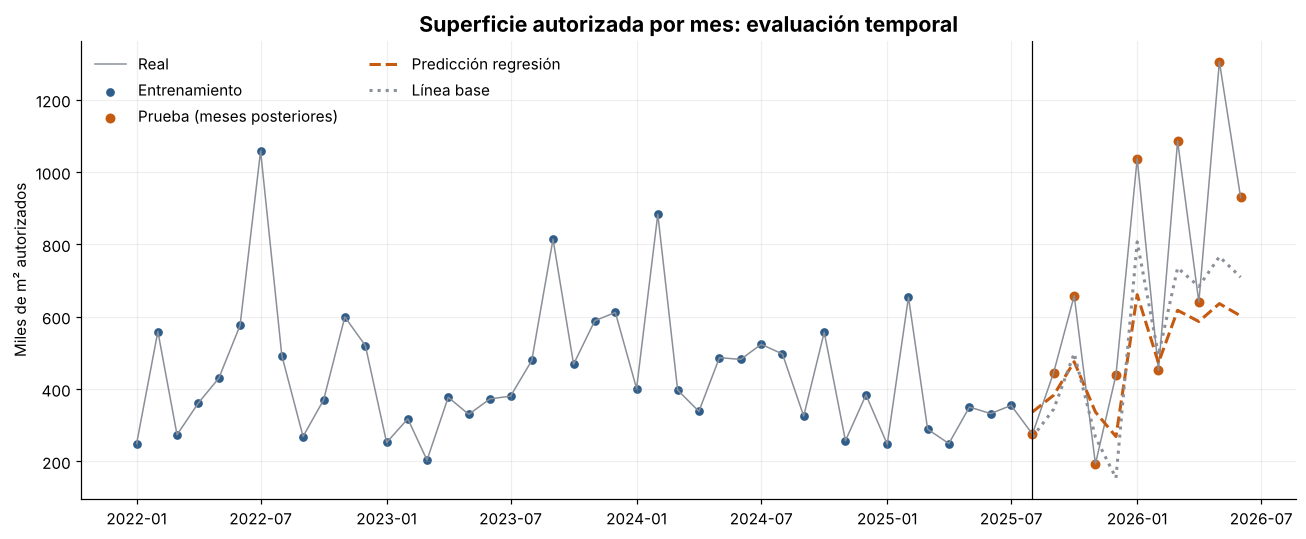

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
x_ts = mensual.index.to_timestamp()
ax.plot(x_ts, ym / 1e3, color=GRIS, lw=1, label="Real")
ax.scatter(x_ts[:corte], y_tr_t / 1e3, s=22, color=AZUL, label="Entrenamiento")
ax.scatter(x_ts[corte:], y_te_t / 1e3, s=30, color=NARANJA, label="Prueba (meses posteriores)")
ax.plot(x_ts[corte:], pred_b / 1e3, color=NARANJA, ls="--", lw=2, label="Predicción regresión")
ax.plot(x_ts[corte:], pred_base / 1e3, color=GRIS, ls=":", lw=2, label="Línea base")
ax.axvline(x_ts[corte], color="black", lw=.8)
ax.set_title("Superficie autorizada por mes: evaluación temporal")
ax.set_ylabel("Miles de m² autorizados"); ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); guardar(fig, "modelo_mensual_temporal.png"); plt.show()

## 7. Conclusiones

1. **El R² de 0.999 es un artefacto.** `Inversión Total` es `Metros Cuadrados × tarifa`, con solo dos tarifas
   (RD$ 61,600 y RD$ 57,200 por m²). Ningún modelo sobre estas dos columnas aporta conocimiento nuevo.
2. **Uso correcto del dato:** sirve para documentar la regla de valoración del MIVHED, no para estimar el costo
   real de una obra.
3. **La evaluación importa tanto como el modelo.** Con partición aleatoria, el modelo mensual parecía explicar
   58% de la variación; dependiendo solo de la semilla, ese número podía ir de
   -1.39 a 0.62. Evaluado sobre meses posteriores: R² = 0.23.
4. **Una regla simple gana a la regresión.** Multiplicar las licencias del mes por la superficie promedio por licencia del pasado (≈ 5,143 m²) obtiene R² = 0.51 y menor error (MAE ≈ 187 mil m² frente a 230 mil m²) en los meses de prueba, y gana en 3 de 4 ventanas de la validación cruzada temporal. La regresión no aporta valor sobre esa regla; el modelo mensual sirve como referencia de orden de magnitud, no como pronóstico.

### Limitaciones
- 54 meses es una serie corta; cualquier conclusión sobre el modelo mensual es preliminar.
- En 2026 la superficie autorizada sube con fuerza frente a años anteriores; ningún modelo entrenado solo con el pasado lo anticipa bien.
- No se modela estacionalidad ni variables como provincia o tipología, que explicarían mejor la superficie.
- El hallazgo depende de la versión publicada del dataset (actualización 21/07/2026).

### Recomendación al publicador
Indicar en la ficha del dataset que `Inversión Total` es un valor **calculado** y publicar la tabla de tarifas
y su vigencia. Evitaría que otros analistas lo traten como una inversión observada.

---
*Trabajo original: grupo Los del Prompt — Alejandra Espinal, Erick Peña, Evans Gregorio, Lisbeth Pinales,
Mariano Duran (Maestría en Ciencia de Datos e IA, Inteligencia Artificial I). Reestructuración y evaluación
temporal del modelo mensual: Mariano Duran.*